# 01 · Preprocessing — Filbin 2018 pediatric H3-K27M glioma (malignant compartment)

Pediatric diffuse midline glioma (H3-K27M), SmartSeq2, TPM expression. Isolate the
malignant compartment, threshold thin samples by a **data-driven multiplicative
gap** (checking whether the C3 "clean count gap" premise actually holds here),
integrate patients with Harmony across an **integration-strength sweep** (Gate 1 is
judged on the regenerated embedding, never a scalar), embed, and strip detached
islands. H3-K27M glioma carries a documented developmental hierarchy — a **cycling
OPC-like progenitor pool** that differentiates into post-mitotic **OC-like** and **AC-like** states along a **branching** trajectory — so 02_manifold settles each region's biology (embryonic signatures **and**
cell cycle) *before* the Gate-1 GO, and check whether the cycling compartment is a
proliferation-confounded lobe to scope out (the Kürten fork) or the developmental origin. The cell-cycle-based scoping decision (which cycling clusters, if any, to remove) is made in 02_manifold before the tree is fit.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Filbin2018_Brain-7'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
raw  = re.sub(r'-\d+$', '', name)                       # strip attempt suffix -> 'Filbin2018_Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw input:', 'Data_'+raw)

dataset: Filbin2018_Brain-7 | category: Brain | raw input: Data_Filbin2018_Brain


### Load malignant compartment
Filbin et al. annotate cell type directly (SmartSeq2, TPM); the loader passes TPM
through and log1p-transforms. We take the `Malignant` calls (normal oligodendrocytes
and macrophages are dropped).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell types:', adata.obs.cell_type.value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
# published Filbin annotations carried in obs -> numeric
for cnm in ['oc_like','ac_like','opc_like','opc_variable','g1s_score','g2m_score','mp_top_score']:
    adata.obs[cnm] = pd.to_numeric(adata.obs[cnm], errors='coerce')
adata.obs['cc_score'] = adata.obs[['g1s_score','g2m_score']].max(axis=1)

Loading ../../../../../../data/unzip/CCCA/Data_Filbin2018_Brain
Done.
full atlas: (2587, 23686) | cell types: {'Malignant': 2259, 'Oligodendrocyte': 232, 'Macrophage': 96}
malignant: (2259, 23686) | samples: 6


### Sample thresholding — the "clean count gap" premise is checked, not assumed
Per-sample malignant counts decline **smoothly** (667 → 141) with no order-of-magnitude
gap. A median-restricted multiplicative gap-finder is run for the record; its widest
interior gap (241 → 141, ratio 1.71) is not a genuine inflection, and the smallest
sample (MUV01, 141 cells) sits well above the ~100-cell precedent floor and intermixes
on the manifold (below). The C3 premise of a clean count gap does **not** hold here, so
no sample is dropped — cutting a well-populated, well-integrated 141-cell patient would
be over-aggressive.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
floor = 0.10 * vals.max()
valid = [i for i in range(len(ratios)) if i >= 1 and vals[i] >= floor and vals[i+1] >= floor]
print('sorted per-sample counts:', n.to_dict())
print('multiplicative ratios across gaps:', np.round(ratios,2).tolist())
if valid:
    gap = max(valid, key=lambda i: ratios[i])
    cand = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'widest interior gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); candidate cut = {cand}')
print(f'smallest sample = {int(vals.min())} cells (>= ~100 precedent floor)')
print('decision: no clean count gap -> keep all', len(n), 'samples')
# keep all samples
print('cells after threshold:', adata.shape[0])

sorted per-sample counts: {'MUV05': 667, 'BCH869': 489, 'BCH836': 438, 'MUV10': 283, 'BCH1126': 241, 'MUV01': 141}
multiplicative ratios across gaps: [1.36, 1.12, 1.55, 1.17, 1.71]
widest interior gap: 241 -> 141 (ratio 1.71); candidate cut = 184
smallest sample = 141 cells (>= ~100 precedent floor)
decision: no clean count gap -> keep all 6 samples
cells after threshold: 2259


### Overdispersion, PCA, Harmony integration-strength sweep (Gate 1)
Overdispersed genes → 50-PC PCA. Gate 1 is decided on the **regenerated embedding**
across a Harmony θ sweep, not on a scalar. `n_pcs=18` matches the reference scale
(Puram 40 / Kürten 20; the documented n_pcs=6 under-powering is avoided). The sweep
(θ ∈ {0,1,2,4}) is rendered in the diagnostic below; θ=0 is a per-patient
archipelago, θ=1 fully intermixes all six patients into one continuous mass while
preserving the developmental structure (cycling pole + differentiated fan), θ≥2
begins eroding that structure. We commit **θ=1**.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('PCA variance ratio [:12]:', np.round(adata.uns['pca']['variance_ratio'][:12],4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3779 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3779
PCA variance ratio [:12]: [0.0527, 0.0228, 0.0166, 0.0138, 0.013, 0.0051, 0.0045, 0.0038, 0.0032, 0.0028, 0.0024, 0.0023]


mean cross-sample kNN fraction by theta: {0: 0.028, 1: 0.612, 2: 0.675, 4: 0.704}


2026-08-08 20:28:33,900 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 20:28:34,253 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 20:28:34,262 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 20:28:34,632 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 20:28:35,005 - harmonypy - INFO - Iteration 3 of 30
2026-08-08 20:28:35,387 - harmonypy - INFO - Iteration 4 of 30
2026-08-08 20:28:35,745 - harmonypy - INFO - Converged after 4 iterations
2026-08-08 20:28:39,219 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 20:28:39,605 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 20:28:39,615 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 20:28:39,984 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 20:28:40,367 - harmonypy - INFO - Iteration 3 of 30
2026-08-08 20:28:40,722 - harmonypy - INFO - Iteration 4 of 30
2026-08-08 20:28:41,039 - harmonypy - INFO - Iteration 5 of 

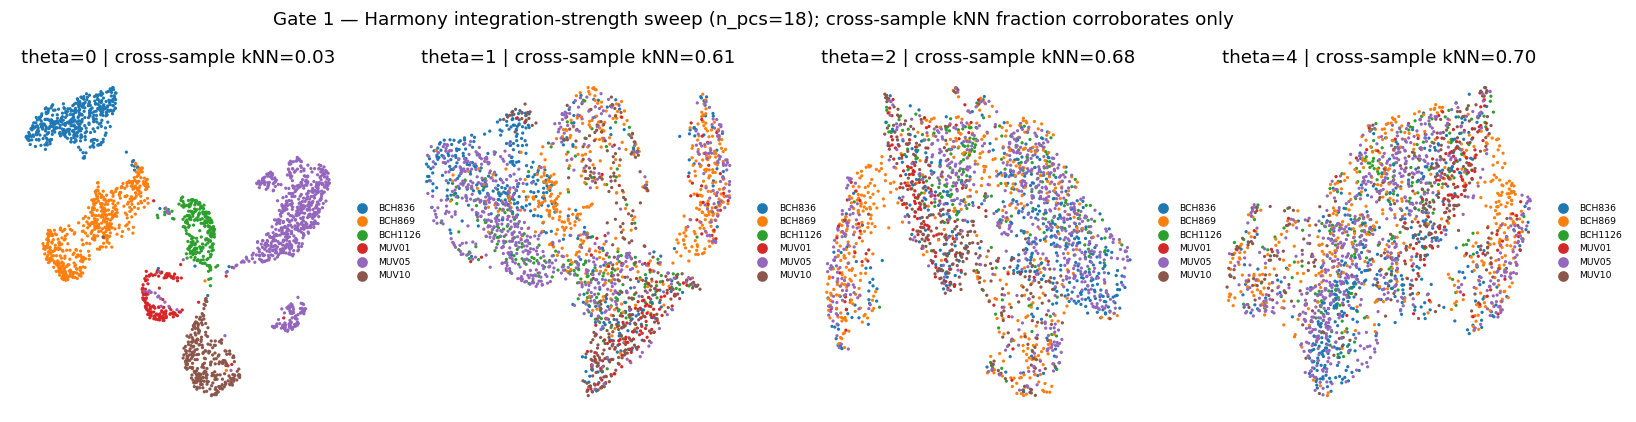

In [6]:
# Harmony integration-strength sweep -> Gate 1 judged on the embedding
NPCS = 18
def embed(theta):
    ad = adata.copy()
    if theta == 0:
        ad.obsm['X_pca_harmony'] = ad.obsm['X_pca'].copy()
    else:
        sce.pp.harmony_integrate(ad, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(ad, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
    sc.tl.umap(ad, spread=1.0, min_dist=0.5, random_state=SEED)
    kk = NearestNeighbors(n_neighbors=16).fit(ad.obsm['X_umap']).kneighbors(ad.obsm['X_umap'], return_distance=False)[:,1:]
    s = ad.obs['sample'].values
    mix = float(np.mean([(s[kk[i]] != s[i]).mean() for i in range(ad.n_obs)]))
    return ad, mix
sweep = {}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, th in zip(axes, [0,1,2,4]):
    adx, mix = embed(th); sweep[th] = (adx, mix)
    sc.pl.umap(adx, color='sample', size=18, frameon=False, show=False, ax=ax,
               legend_fontsize=6, title=f'theta={th} | cross-sample kNN={mix:.2f}')
fig.suptitle('Gate 1 — Harmony integration-strength sweep (n_pcs=18); cross-sample kNN fraction corroborates only', y=1.02)
plt.show()
print('mean cross-sample kNN fraction by theta:', {k: round(v[1],3) for k,v in sweep.items()})

In [7]:
# commit theta=1 (mixed + continuous, structure preserved)
adata, mix1 = sweep[1]
print(f'committed theta=1: {adata.obs["sample"].nunique()} patients, cross-sample kNN fraction = {mix1:.2f}')

committed theta=1: 6 patients, cross-sample kNN fraction = 0.61


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and keep
only the largest connected component — strips physically detached specks while keeping
the continuous manifold. Filbin's manifold is already fully connected (0 cells removed),
consistent with one continuous compartment.

In [8]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands removed:', int((lab!=main).sum()), 'cells in', ncomp-1, 'islands')
adata = adata[lab==main].copy()
print('cells after island removal:', adata.shape[0])

detached islands removed: 0 cells in 0 islands
cells after island removal: 2259


### Subtype annotation — data markers + Filbin's published cell states
Following the standing rule that annotation uses **both** data-derived markers **and**
the publication's reported programs: Filbin et al. resolve H3-K27M glioma into an
**OPC-like** cycling progenitor pool that differentiates into **OC-like** (oligodendrocyte)
and **AC-like** (astrocyte) states. The dataset carries their per-cell `opc_like` /
`oc_like` / `ac_like` scores; each malignant cell is assigned by the argmax of those three
(data-derived confirmation via lineage markers below), giving the published three-state
hierarchy. Cell-cycle phase (Filbin's `cell_cycle_phase`) marks the cycling progenitor pool.

In [9]:
states = adata.obs[['opc_like','oc_like','ac_like']].values
adata.obs['subtype'] = pd.Categorical(
    np.array(['OPC-like','OC-like','AC-like'])[np.nanargmax(states, axis=1)],
    categories=['OPC-like','OC-like','AC-like'], ordered=True)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('published cell-state composition:', adata.obs['subtype'].value_counts().to_dict())
# data-derived marker confirmation of the published states
markers = {'OPC-like':['PDGFRA','OLIG1','OLIG2','CSPG4'],
           'OC-like':['MBP','PLP1','MOG','CLDN11','SOX10'],
           'AC-like':['GFAP','AQP4','APOE','S100B']}
def sig(gs):
    gg=[g for g in gs if g in adata.var_names]
    return np.asarray(adata[:,gg].X.mean(1)).ravel()
for k,gs in markers.items(): adata.obs['m_'+k]=sig(gs)
prof = adata.obs.groupby('subtype', observed=True)[['m_'+k for k in markers]].mean().round(2)
print('mean lineage-marker score per published state (rows=assigned state):')
print(prof.to_string())
print('cycling fraction by state:', adata.obs.groupby('subtype',observed=True)['cycling'].mean().round(3).to_dict())

published cell-state composition: {'OPC-like': 1199, 'OC-like': 611, 'AC-like': 449}
mean lineage-marker score per published state (rows=assigned state):
          m_OPC-like  m_OC-like  m_AC-like
subtype                                   
OPC-like        4.28       2.03       2.22
OC-like         4.47       2.66       2.10
AC-like         1.37       1.91       5.01
cycling fraction by state: {'OPC-like': 0.171, 'OC-like': 0.206, 'AC-like': 0.1}


### Gate 1 — batch mixing & manifold continuity (decided on the embedding)
The θ sweep above shows the malignant cells from all six patients intermix on **one
continuous connected manifold** at θ=1 (no per-patient archipelago as at θ=0, no
detached islands). Structure is preserved: a cycling OPC-like pole grades into the
OC-like/AC-like differentiated fan. **Gate 1 = GO.**

Gate 1: six patients intermixed on one continuous manifold, 0 detached islands -> GO


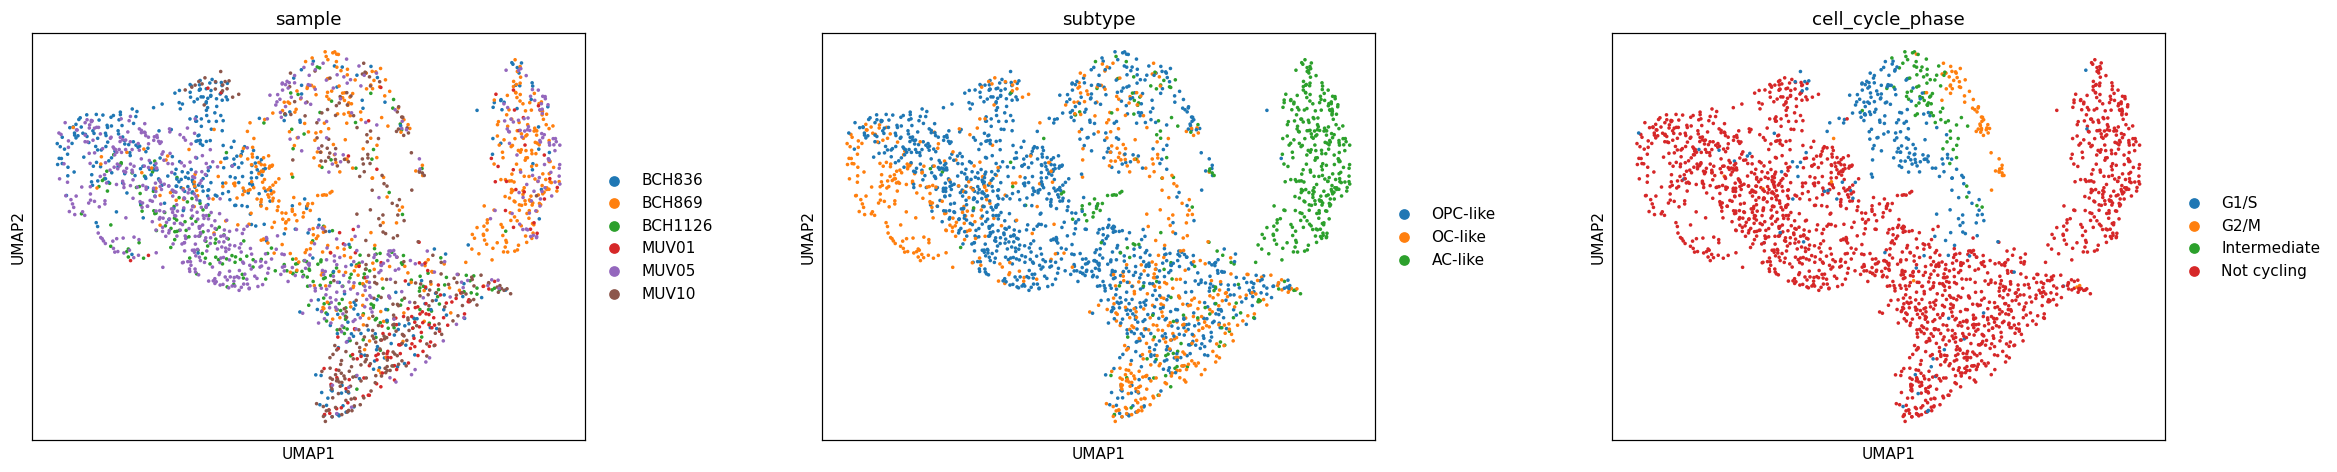

In [10]:
fig = sc.pl.umap(adata, color=['sample','subtype','cell_cycle_phase'], size=22, wspace=.3, show=False)
print('Gate 1: six patients intermixed on one continuous manifold, 0 detached islands -> GO')

### Save processed data

In [11]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2259, 21224)


### Sample-integration figure (deliverable `samples.pdf`)
Puram branching house style: `figsize=(5,5)`, `size=180`, colour = sample, native embedding,
axes inverted. Cross-sample intermixing across the manifold is the Gate-1 batch-integration
evidence (all six patients overlap on one connected structure).

saved samples.pdf | malignant cells: 2259


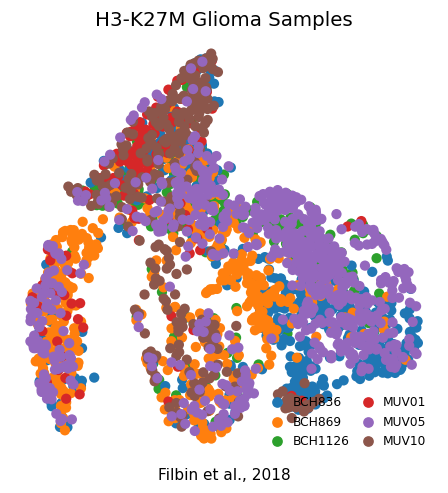

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
sc.pl.umap(adata, color='sample', size=180, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h,l = ax.get_legend_handles_labels()
ax.legend(h,l, ncol=2, frameon=False, loc='lower right', columnspacing=.5,
          handletextpad=.25, fontsize=8)
ax.set_title('H3-K27M Glioma Samples', size=13)
ax.text(.5,-.05,'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show(); print('saved samples.pdf | malignant cells:', adata.shape[0])